# Задача 3. Цвета клеток картинками из MNIST

Среда `MnistGridWorldEnv` (`src/envs/mnist_env.py`) — копия обычной, но вместо one-hot цвета агент видит
**случайную картинку цифры** этого цвета (цвет 2 → случайная двойка из MNIST), 14x14, вектор из 196 чисел.
Цифр всего 10, поэтому цветов пола не больше 7 (+3 служебных): **Env1 (25 уникальных цветов) исключён**, берём Env2–Env4.

Главное сравнение — **one-hot против MNIST** при тех же картах и тех же гиперпараметрах
(one-hot прогоны берутся из `outputs/task2/runs`). Результаты — в `outputs/task3/`.

In [1]:
import json
import os
import sys
from pathlib import Path

# работаем из корня репозитория: там лежат src/ и outputs/
if Path.cwd().name == "tasks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import numpy as np
import torch

from src import utils
from src.envs import make_env, optimal_stats
from src.models import DSAC, PPO

# Режим запуска. При обычном открытии ноутбука: полное обучение всех экспериментов и все графики.
# На сервере скрипт задаёт переменные окружения, чтобы запускать эксперименты параллельно:
#   RUN_MODE=smoke|full, RUN_ONLY=<имя эксперимента> (пусто — все), RUN_STAGES=train,plots
RUN_MODE = os.environ.get("RUN_MODE", "full")
RUN_ONLY = os.environ.get("RUN_ONLY", "")
RUN_STAGES = os.environ.get("RUN_STAGES", "train,plots").split(",")
torch.set_num_threads(1)  # много прогонов идут параллельно, каждому хватит одного потока CPU
CUDA = torch.cuda.is_available()
print("режим:", RUN_MODE, "| эксперимент:", RUN_ONLY or "все", "| этапы:", RUN_STAGES, "| CUDA:", CUDA)

SETUPS = {
    1: dict(h=5, w=5, n_colors=None, obstacle_fraction=0.0),  # 25 уникальных цветов — MDP
    2: dict(h=5, w=5, n_colors=5, obstacle_fraction=0.0),
    3: dict(h=10, w=10, n_colors=7, obstacle_fraction=0.1),
    4: dict(h=10, w=10, n_colors=4, obstacle_fraction=0.1),
}

from src.envs import load_mnist
del SETUPS[1]  # 25 цветов не помещаются в 10 цифр

режим: full | эксперимент: ppo_mnist_env3_gru_seed0 | этапы: ['train'] | CUDA: True


## Проверка наблюдений

Картинка должна быть из класса, равного цвету клетки; размер 196, тип float32, значения от 0 до 1.

размер: (196,) тип: float32 диапазон: 0.0 0.9019608


проверено шагов: 200 — все картинки из правильного класса


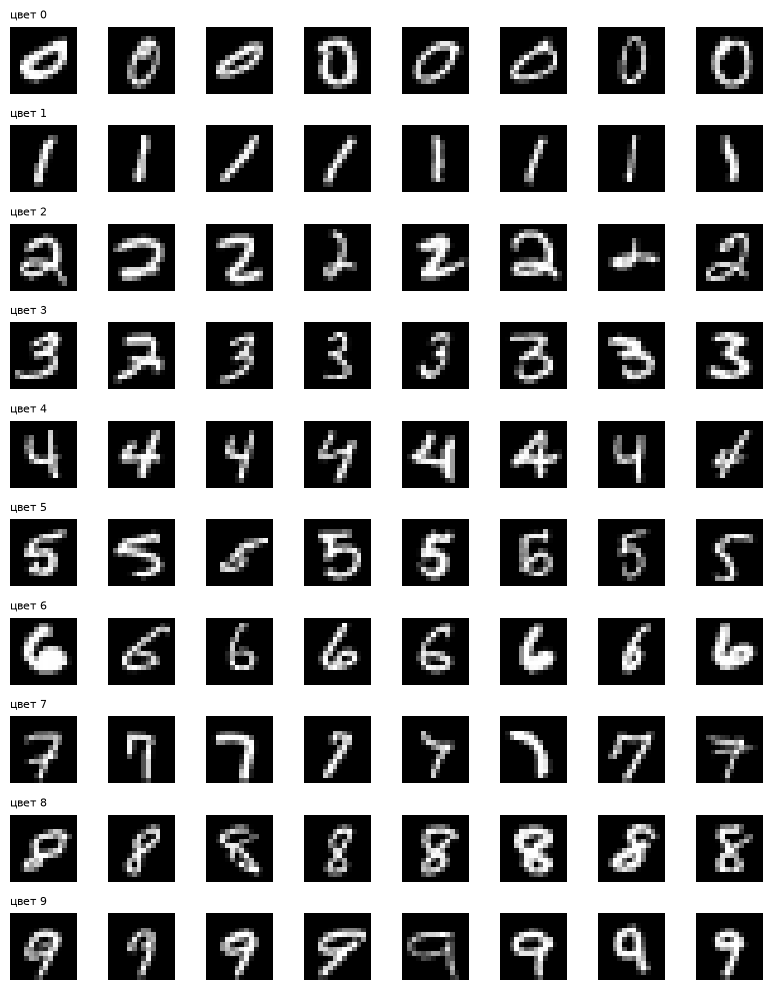

In [2]:
images = load_mnist()
env = make_env(**SETUPS[3], seed=0, mnist=True)
obs, info = env.reset(seed=0)
print("размер:", obs.shape, "тип:", obs.dtype, "диапазон:", obs.min(), obs.max())
checked = 0
for t in range(200):
    obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
    # картинка должна в точности совпадать с одной из картинок цифры info["color"]
    digit_pictures = images[info["color"]]
    assert np.abs(digit_pictures - obs).sum(axis=1).min() == 0, "картинка не из своего класса"
    checked += 1
    if terminated or truncated:
        obs, info = env.reset()
print("проверено шагов:", checked, "— все картинки из правильного класса")

fig, axes = plt.subplots(10, 8, figsize=(8, 10))
for digit in range(10):
    for j in range(8):
        axes[digit, j].imshow(images[digit][np.random.randint(len(images[digit]))].reshape(14, 14), cmap="gray")
        axes[digit, j].axis("off")
    axes[digit, 0].set_title(f"цвет {digit}", fontsize=8, loc="left")
fig.tight_layout()
Path("outputs/task3/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("outputs/task3/figures/mnist_colors.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
# Базовые гиперпараметры (те же, что в первой версии ноутбуков). Для каждого эксперимента делаем копию и меняем нужное.
ppo_cfg = {
    "device": "cpu",  # PPO на GPU не быстрее (замер на сервере: 479 против 429 шагов/с)
    "env_seed": 0,  # от него зависит карта
    "seed": 0,  # от него зависят сеть и старты эпизодов
    "memory": True,  # True — GRU, False — MLP без памяти
    "episodes_per_update": 10,  # сколько эпизодов собрать перед обновлением
    "epochs": 4,
    "episodes_per_batch": 5,
    "gamma": 0.99,
    "gae_lambda": 0.95,
    "lr": 3e-4,
    "clip": 0.2,
    "ent_coef": 0.01,
    "vf_coef": 0.5,
    "hidden": 128,
    "save_every": 50,  # как часто сохранять метрики и веса на диск
}
dsac_cfg = {
    "device": "cuda" if CUDA else "cpu",  # DSAC на GPU в ~3 раза быстрее (167 против 52 шагов/с)
    "env_seed": 0,
    "seed": 0,
    "memory": True,
    "soft_q": True,  # мягкая Q (энтропия в цели критика) или обычная
    "buffer_episodes": 5000,  # сколько последних эпизодов помнить
    "learning_starts": 20,  # сколько эпизодов только копим опыт, не учась
    "updates_per_episode": 4,  # сколько обновлений после каждого эпизода
    "batch_size": 8,  # сколько случайных эпизодов из буфера в одном обновлении
    "gamma": 0.99,
    "tau": 0.005,  # скорость, с которой target-критики догоняют обычных
    "lr": 3e-4,
    "alpha": 0.005,  # температура: вес энтропии
    "hidden": 128,
    "save_every": 25,
}
# число эпизодов обучения: на больших картах дольше. В режиме smoke — коротко, только проверить, что всё работает
EPISODES = {
    "full": {"ppo": {1: 1000, 2: 1000, 3: 1500, 4: 1500}, "dsac": {1: 500, 2: 500, 3: 800, 4: 800}},
    "smoke": {"ppo": {1: 20, 2: 20, 3: 20, 4: 20}, "dsac": {1: 8, 2: 8, 3: 4, 4: 4}},
}
EVAL_EPISODES = {"full": 100, "smoke": 5}

# smoke-прогоны пишем отдельно, чтобы не смешать их с полными
OUT = "outputs/task3" if RUN_MODE == "full" else "runs/smoke/task3"

## Эксперименты: те же гиперпараметры, что в задаче 2, только `"mnist": True`

In [4]:
EXPERIMENTS = []
for i in SETUPS:
    for algo, base in [("ppo", ppo_cfg), ("dsac", dsac_cfg)]:
        name = f"{algo}_mnist_env{i}_gru_seed0"
        EXPERIMENTS.append({"name": name, "algo": algo, "cfg": {
            **base, **SETUPS[i], "mnist": True, "episodes": EPISODES[RUN_MODE][algo][i],
            "budget": RUN_MODE, "out_dir": f"{OUT}/runs", "run_name": name}})
for exp in EXPERIMENTS:
    print(exp["name"], "| эпизодов:", exp["cfg"]["episodes"], "|", exp["cfg"]["device"])

ppo_mnist_env2_gru_seed0 | эпизодов: 1000 | cpu
dsac_mnist_env2_gru_seed0 | эпизодов: 500 | cuda
ppo_mnist_env3_gru_seed0 | эпизодов: 1500 | cpu
dsac_mnist_env3_gru_seed0 | эпизодов: 800 | cuda
ppo_mnist_env4_gru_seed0 | эпизодов: 1500 | cpu
dsac_mnist_env4_gru_seed0 | эпизодов: 800 | cuda


In [5]:
def run_experiment(exp):
    """Обучает модель, оценивает её и сохраняет всё в OUT/runs/<имя>/ и OUT/eval/."""
    run_dir = Path(OUT) / "runs" / exp["name"]
    status_file = run_dir / "status.json"
    if status_file.exists() and json.loads(status_file.read_text())["status"] == "completed":
        print("уже готово, пропускаю:", exp["name"])
        return
    print("=" * 20, exp["name"], "=" * 20)
    if exp["algo"] == "ppo":
        alg = PPO(exp["cfg"])
    else:
        alg = DSAC(exp["cfg"])
    alg.train()

    # оценка на одних и тех же стартах (сиды 10000, 10001, ...): жадно и с сэмплированием действий
    n = EVAL_EPISODES[RUN_MODE]
    greedy = alg.evaluate(n, greedy=True)
    sampled = alg.evaluate(n, greedy=False)
    results = {"budget": RUN_MODE,
               "greedy": utils.eval_summary(greedy, alg.cfg["gamma"], alg.optimal),
               "stochastic": utils.eval_summary(sampled, alg.cfg["gamma"], alg.optimal)}
    utils.save_eval(alg.run_dir, results)
    print("оценка:", json.dumps(results, ensure_ascii=False))

    # тепловая карта и GIF — по эпизодам с сэмплированием (так агент действует при обучении)
    eval_dir = Path(OUT) / "eval"
    eval_dir.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(6, 6))
    image = utils.plot_heatmap(ax, alg.env, sampled)
    fig.colorbar(image, ax=ax, fraction=0.046, label="посещений за эпизод")
    s = results["stochastic"]
    ax.set_title(f"{exp['name']}: success {s['success_rate']:.2f}, длина {s['mean_length']:.1f} "
                 f"(оптимум {s['optimal_length']:.1f})", fontsize=9)
    fig.savefig(eval_dir / f"{exp['name']}_heatmap.png", dpi=150, bbox_inches="tight")
    plt.close(fig)
    short = [ep for ep in sampled if ep["length"] <= 60][:5]
    if len(short) == 0:
        short = sampled[:1]
    utils.save_gif(alg.env, short, eval_dir / f"{exp['name']}.gif", exp["name"])


if "train" in RUN_STAGES:
    for exp in EXPERIMENTS:
        if RUN_ONLY == "" or RUN_ONLY == exp["name"]:
            run_experiment(exp)

==================== ppo_mnist_env3_gru_seed0 ====================


episode 100 | steps 14906 | return 0.424 (opt 0.938) | length 149.1 | entropy 1.31


episode 200 | steps 25280 | return 0.508 (opt 0.938) | length 103.7 | entropy 1.27


episode 300 | steps 34455 | return 0.534 (opt 0.938) | length 91.8 | entropy 1.27


episode 400 | steps 39872 | return 0.659 (opt 0.938) | length 54.2 | entropy 1.12


...

episode 1300 | steps 65825 | return 0.805 (opt 0.938) | length 25.1 | entropy 0.54


episode 1400 | steps 68648 | return 0.808 (opt 0.938) | length 28.2 | entropy 0.54


episode 1500 | steps 71522 | return 0.804 (opt 0.938) | length 28.7 | entropy 0.53


оценка: {"budget": "full", "greedy": {"episodes": 100, "success_rate": 1.0, "failures": 0, "mean_return": 0.8650448906965537, "mean_length": 16.85, "mean_success_length": 16.85, "optimal_length": 7.47191011235955, "optimal_return": 0.9375444197536404}, "stochastic": {"episodes": 100, "success_rate": 1.0, "failures": 0, "mean_return": 0.8254139559074073, "mean_length": 21.72, "mean_success_length": 21.72, "optimal_length": 7.47191011235955, "optimal_return": 0.9375444197536404}}


saved outputs/task3/eval/ppo_mnist_env3_gru_seed0.gif


## One-hot против MNIST

In [6]:
plt.style.use("seaborn-v0_8-darkgrid")
COLORS = ["tab:red", "tab:blue", "tab:green", "tab:orange", "tab:purple"]


def load_metrics(name):
    """metrics.csv прогона как словарь {колонка: np.array}; None, если прогона нет."""
    path = Path(OUT) / "runs" / name / "metrics.csv"
    if not path.exists():
        print("нет данных:", name)
        return None
    import csv
    with open(path, encoding="utf-8") as f:
        rows = list(csv.DictReader(f))
    data = {}
    for key in rows[0]:
        values = []
        for row in rows:
            if row[key] == "True":
                values.append(1.0)
            elif row[key] == "False":
                values.append(0.0)
            elif row[key] in ("", "nan"):
                values.append(np.nan)
            else:
                values.append(float(row[key]))
        data[key] = np.array(values)
    return data


def plot_curve(ax, values, label, color, window=50):
    """Линия — скользящее среднее за window эпизодов, полоса — скользящее стандартное отклонение
    внутри ОДНОГО прогона (1 сид). Это не доверительный интервал по сидам."""
    means, stds = [], []
    for i in range(len(values)):
        last = values[max(0, i - window + 1):i + 1]
        last = last[~np.isnan(last)]
        means.append(np.mean(last) if len(last) else np.nan)
        stds.append(np.std(last) if len(last) else np.nan)
    means, stds = np.array(means), np.array(stds)
    x = np.arange(len(values))
    ax.plot(x, means, color=color, linewidth=2, label=label)
    ax.fill_between(x, means - stds, means + stds, color=color, alpha=0.25)


def plot_metric_grid(names, labels, key, ylabel, title, filename, optimal_key=None):
    """По графику на каждую среду; на графике — несколько прогонов (names[i] — список имён для Env i+1)."""
    fig, axes = plt.subplots(1, len(names), figsize=(5.5 * len(names), 4.3), squeeze=False)
    for ax, (env_name, run_names) in zip(axes[0], names.items()):
        for j, (run, label) in enumerate(zip(run_names, labels)):
            data = load_metrics(run)
            if data is None:
                continue
            plot_curve(ax, data[key], label, COLORS[j])
            if optimal_key is not None and j == 0:
                config = json.loads((Path(OUT) / "runs" / run / "config.json").read_text())
                ax.axhline(config["optimal"][optimal_key], color="black", linestyle=":", label="оптимум (oracle)")
        ax.set_title(f"{env_name}")
        ax.set_xlabel("эпизод")
        ax.set_ylabel(ylabel)
        if key == "length":
            ax.set_yscale("log")
        ax.legend(fontsize=8)
    fig.suptitle(f"{title} (линия — скользящее среднее за 50 эпизодов, полоса — ± ст. откл. в окне; 1 сид)")
    fig.tight_layout()
    path = Path(OUT) / "figures" / filename
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


def eval_table(names):
    """Таблица итоговой оценки по сохранённым eval.json."""
    rows = []
    for name in names:
        path = Path(OUT) / "runs" / name / "eval.json"
        if not path.exists():
            rows.append({"run": name, "status": "pending"})
            continue
        result = json.loads(path.read_text(encoding="utf-8"))
        for mode in ["greedy", "stochastic"]:
            r = result[mode]
            rows.append({"run": name, "budget": result["budget"], "eval": mode,
                         "success_rate": round(r["success_rate"], 3), "mean_return": round(r["mean_return"], 3),
                         "mean_length": round(r["mean_length"], 1),
                         "mean_success_length": None if r["mean_success_length"] is None else round(r["mean_success_length"], 1),
                         "failures": r["failures"], "optimal_length": round(r["optimal_length"], 2)})
    return rows

In [7]:
TASK2_RUNS = Path("outputs/task2/runs")


def link_onehot(name):
    """Чтобы рисовать одной функцией, временно читаем one-hot прогоны из outputs/task2."""
    return str(Path("..") / ".." / "task2" / "runs" / name)


if "plots" in RUN_STAGES:
    for algo in ["ppo", "dsac"]:
        names = {f"Env{i}": [link_onehot(f"{algo}_env{i}_gru_seed0"), f"{algo}_mnist_env{i}_gru_seed0"] for i in SETUPS}
        A = algo.upper()
        plot_metric_grid(names, ["one-hot цвет", "картинка MNIST"], "return", "средняя дисконтированная отдача",
                         f"{A}: one-hot против MNIST", f"{algo}_onehot_vs_mnist_return.png", "return")
        plot_metric_grid(names, ["one-hot цвет", "картинка MNIST"], "length", "длина эпизода",
                         f"{A}: длина эпизода, one-hot против MNIST", f"{algo}_onehot_vs_mnist_length.png", "length")

## Итоговая оценка

In [8]:
if "plots" in RUN_STAGES:
    rows = eval_table([exp["name"] for exp in EXPERIMENTS])
    rows += eval_table([link_onehot(f"{algo}_env{i}_gru_seed0") for algo in ["ppo", "dsac"] for i in SETUPS])
    import csv
    table_dir = Path(OUT) / "tables"
    table_dir.mkdir(parents=True, exist_ok=True)
    with open(table_dir / "eval_summary.csv", "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=["run", "status", "budget", "eval", "success_rate", "mean_return",
                                               "mean_length", "mean_success_length", "failures", "optimal_length"])
        writer.writeheader()
        writer.writerows(rows)
    for row in rows:
        print(row)

## Ответы на вопросы задания

*Черновик: перепроверить по графикам и таблице выше и переписать своими словами.*

**1. Что проверяет замена one-hot на MNIST?** Раньше один цвет всегда давал одно и то же наблюдение. Теперь одному
цвету соответствуют тысячи разных картинок, и на каждом шаге приходит новая. Агент должен сначала распознать цифру
(по сути, решить задачу классификации внутри RL) и только потом ориентироваться. Это проверяет работу с более сложными
и зашумлёнными наблюдениями.

**2. Почему задача стала сложнее?** Вход вырос с 8–10 чисел до 196, наблюдения шумные, а сигнал обучения тот же —
редкая награда за достижение цели. Распознаванию цифр сеть учится только через RL-лосс, без меток классов.

**3. Нужен ли более сложный энкодер?** Скорее нет: картинки 14x14, классов 10, с этим справляется даже линейный
классификатор (на MNIST около 92% точности). Поэтому архитектура не менялась: первый слой `Linear(196 + 4 → 128)` + `Tanh`.
CNN дала бы чуть лучшее распознавание ценой усложнения и замедления.

**4. Как изменение наблюдений повлияло на результаты?** *Заполнить по графикам `outputs/task3/figures/*onehot_vs_mnist*` и таблице.*